<a href="https://colab.research.google.com/github/ariansarathy/Brain-Tumor/blob/main/Brain_Tumor_Classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Binary Brain Tumor Classifier (ResNet-50)

Healthy vs. Tumor classification of brain MRI images using transfer learning in PyTorch.

**Before running:** go to **Runtime > Change runtime type**, pick a **GPU** (T4 is fine), then **Runtime > Run all**.

## 1. Check the GPU

In [8]:
import torch
print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU found. Training will be very slow; switch the runtime to GPU.")

PyTorch: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


## 2. Download the dataset
Uses the public Kaggle dataset *Brain MRI Images for Brain Tumor Detection* (folders `yes/` = tumor, `no/` = healthy).

In [9]:
!pip install -q kagglehub
import os
import kagglehub

path = kagglehub.dataset_download("navoneel/brain-mri-images-for-brain-tumor-detection")

# Find the folder whose only subfolders are yes/ and no/
DATA_DIR = None
for root, dirs, files in os.walk(path):
    if set(dirs) == {"yes", "no"}:
        DATA_DIR = root
        break

if DATA_DIR is None:
    raise RuntimeError(f"Could not find a folder with only yes/ and no/ inside {path}")

for c in ("no", "yes"):
    print(f"{c}/: {len(os.listdir(os.path.join(DATA_DIR, c)))} images")
print("DATA_DIR =", DATA_DIR)

Using Colab cache for faster access to the 'brain-mri-images-for-brain-tumor-detection' dataset.
no/: 98 images
yes/: 155 images
DATA_DIR = /kaggle/input/brain-mri-images-for-brain-tumor-detection/brain_tumor_dataset


## 3. Model, data pipeline, training and evaluation code

In [10]:
"""
Binary Brain Tumor Classifier (Healthy vs. Tumor)
ResNet-50 transfer learning pipeline in PyTorch, written for Google Colab.

Expected dataset layout (torchvision ImageFolder):
    DATA_DIR/
        no/    <- healthy MRI slices  (label 0)
        yes/   <- tumor MRI slices    (label 1)

Folder names are configurable in Config (negative_class / positive_class), so
layouts like healthy/ + tumor/ work too. Labels are remapped explicitly, so the
result never depends on alphabetical folder order.

Colab quick start (example with the Kaggle "Brain MRI Images for Brain Tumor
Detection" dataset):
    !pip install -q kagglehub
    import kagglehub
    path = kagglehub.dataset_download("navoneel/brain-mri-images-for-brain-tumor-detection")
    print(path)  # point Config.data_dir at the folder that holds yes/ and no/
Then: Runtime > Change runtime type > GPU, and run this file.
"""

import random
import time
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, Optional, Tuple

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from PIL import Image
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms


# ----------------------------------------------------------------------------
# Configuration
# ----------------------------------------------------------------------------
@dataclass
class Config:
    data_dir: str = "/content/brain_tumor_dataset"
    negative_class: str = "no"    # folder name for Healthy -> label 0
    positive_class: str = "yes"   # folder name for Tumor   -> label 1

    image_size: int = 224
    batch_size: int = 32
    num_workers: int = 2
    val_split: float = 0.2

    num_epochs: int = 10
    lr_head: float = 1e-3         # new classifier head learns fast
    lr_backbone: float = 1e-4     # unfrozen pretrained layers learn slowly
    weight_decay: float = 1e-4
    dropout: float = 0.3

    # Pretrained stages to fine-tune; everything else stays frozen.
    trainable_layers: Tuple[str, ...] = ("layer4",)

    patience: int = 3             # early stopping patience (epochs)
    min_delta: float = 1e-4       # minimum val loss drop that counts as improvement
    threshold: float = 0.5        # probability cutoff for the Tumor class

    seed: int = 42
    checkpoint_path: str = "best_resnet50_tumor.pt"


IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
CLASS_NAMES = ["Healthy", "Tumor"]


# ----------------------------------------------------------------------------
# Reproducibility
# ----------------------------------------------------------------------------
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# ----------------------------------------------------------------------------
# Data
# ----------------------------------------------------------------------------
def build_transforms(image_size: int) -> Tuple[transforms.Compose, transforms.Compose]:
    """Augmentation for training only; validation gets a deterministic pipeline."""
    train_tf = transforms.Compose([
        transforms.Resize((image_size, image_size)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(degrees=15),
        transforms.ToTensor(),                              # PIL [H,W,3] -> float [3,224,224] in [0,1]
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),  # per channel standardization
    ])
    eval_tf = transforms.Compose([
        transforms.Resize((image_size, image_size)),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ])
    return train_tf, eval_tf


class LabelRemap:
    """Maps ImageFolder's alphabetical indices to Healthy=0 / Tumor=1."""

    def __init__(self, mapping: Dict[int, int]):
        self.mapping = mapping

    def __call__(self, idx: int) -> int:
        return self.mapping[idx]


def build_dataloaders(cfg: Config) -> Tuple[DataLoader, DataLoader]:
    train_tf, eval_tf = build_transforms(cfg.image_size)

    # Two views of the same files: one augmented, one clean. A shared index
    # split keeps augmentation out of validation. ImageFolder's default loader
    # converts grayscale MRIs to 3 channel RGB, which ResNet expects.
    train_base = datasets.ImageFolder(cfg.data_dir, transform=train_tf)
    val_base = datasets.ImageFolder(cfg.data_dir, transform=eval_tf)

    expected = {cfg.negative_class, cfg.positive_class}
    if set(train_base.classes) != expected:
        raise ValueError(
            f"Expected class folders {sorted(expected)} in {cfg.data_dir}, "
            f"found {train_base.classes}"
        )

    c2i = train_base.class_to_idx
    remap = LabelRemap({c2i[cfg.negative_class]: 0, c2i[cfg.positive_class]: 1})
    train_base.target_transform = remap
    val_base.target_transform = remap

    labels = [remap(t) for t in train_base.targets]
    indices = np.arange(len(labels))
    train_idx, val_idx = train_test_split(
        indices, test_size=cfg.val_split, stratify=labels, random_state=cfg.seed
    )

    train_ds = Subset(train_base, train_idx)
    val_ds = Subset(val_base, val_idx)

    n_pos = int(np.sum(np.array(labels)[train_idx]))
    print(f"Train: {len(train_ds)} images ({n_pos} tumor, {len(train_ds) - n_pos} healthy)")
    print(f"Val:   {len(val_ds)} images")

    pin = torch.cuda.is_available()
    train_loader = DataLoader(train_ds, batch_size=cfg.batch_size, shuffle=True,
                              num_workers=cfg.num_workers, pin_memory=pin)
    val_loader = DataLoader(val_ds, batch_size=cfg.batch_size, shuffle=False,
                            num_workers=cfg.num_workers, pin_memory=pin)
    return train_loader, val_loader


# ----------------------------------------------------------------------------
# Model
# ----------------------------------------------------------------------------
def build_model(cfg: Config) -> nn.Module:
    model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)

    # Freeze the backbone except the stages listed in cfg.trainable_layers.
    for name, param in model.named_parameters():
        param.requires_grad = any(name.startswith(layer) for layer in cfg.trainable_layers)

    # Backbone output after global average pooling: [B, 2048].
    in_features = model.fc.in_features  # 2048
    model.fc = nn.Sequential(
        nn.Dropout(p=cfg.dropout),
        nn.Linear(in_features, 1),   # [B, 2048] -> [B, 1] raw score
        nn.Sigmoid(),                # [B, 1] -> probability of Tumor in (0, 1)
    )
    # New head parameters are trainable by default.
    return model


def build_optimizer(model: nn.Module, cfg: Config) -> torch.optim.Optimizer:
    """Separate learning rates: fast for the new head, slow for pretrained layers."""
    head_params = list(model.fc.parameters())
    head_ids = {id(p) for p in head_params}
    backbone_params = [p for p in model.parameters()
                       if p.requires_grad and id(p) not in head_ids]

    groups = [{"params": head_params, "lr": cfg.lr_head}]
    if backbone_params:
        groups.append({"params": backbone_params, "lr": cfg.lr_backbone})
    return torch.optim.AdamW(groups, weight_decay=cfg.weight_decay)


def count_parameters(model: nn.Module) -> Tuple[int, int]:
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


# ----------------------------------------------------------------------------
# Metrics and early stopping
# ----------------------------------------------------------------------------
def compute_metrics(y_true: np.ndarray, y_prob: np.ndarray, threshold: float) -> Dict[str, float]:
    y_pred = (y_prob >= threshold).astype(int)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="binary", pos_label=1, zero_division=0
    )
    return {
        "accuracy": float((y_pred == y_true).mean()),
        "precision": float(precision),
        "recall": float(recall),   # sensitivity: share of tumors caught
        "f1": float(f1),
    }


class EarlyStopping:
    """Stops training when validation loss stops improving; saves the best weights."""

    def __init__(self, patience: int, min_delta: float, checkpoint_path: str):
        self.patience = patience
        self.min_delta = min_delta
        self.checkpoint_path = checkpoint_path
        self.best_loss = float("inf")
        self.counter = 0

    def step(self, val_loss: float, model: nn.Module) -> bool:
        """Returns True when training should stop."""
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
            torch.save(model.state_dict(), self.checkpoint_path)
            print(f"  Val loss improved to {val_loss:.4f}; checkpoint saved.")
        else:
            self.counter += 1
            print(f"  No improvement ({self.counter}/{self.patience}).")
        return self.counter >= self.patience


# ----------------------------------------------------------------------------
# Train / validate
# ----------------------------------------------------------------------------
def run_epoch(model: nn.Module, loader: DataLoader, criterion: nn.Module,
              device: torch.device, threshold: float,
              optimizer: Optional[torch.optim.Optimizer] = None
              ) -> Tuple[Dict[str, float], np.ndarray, np.ndarray]:
    """One pass over the loader. Trains when an optimizer is given, else evaluates."""
    is_train = optimizer is not None
    model.train(is_train)

    running_loss, n_samples = 0.0, 0
    all_probs, all_labels = [], []

    with torch.set_grad_enabled(is_train):
        for images, labels in loader:
            # images: [B, 3, 224, 224] float, labels: [B] int64
            images = images.to(device, non_blocking=True)
            labels = labels.float().unsqueeze(1).to(device, non_blocking=True)  # [B] -> [B, 1]

            probs = model(images)               # [B, 1], each value in (0, 1)
            loss = criterion(probs, labels)     # scalar, mean BCE over the batch

            if is_train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()

            batch_size = images.size(0)
            running_loss += loss.item() * batch_size
            n_samples += batch_size
            all_probs.append(probs.detach().squeeze(1).cpu())   # [B]
            all_labels.append(labels.squeeze(1).cpu())          # [B]

    y_prob = torch.cat(all_probs).numpy()                # [N]
    y_true = torch.cat(all_labels).numpy().astype(int)   # [N]

    metrics = compute_metrics(y_true, y_prob, threshold)
    metrics["loss"] = running_loss / n_samples
    return metrics, y_true, y_prob


def fmt(m: Dict[str, float]) -> str:
    return (f"loss {m['loss']:.4f} | acc {m['accuracy']:.4f} | prec {m['precision']:.4f} "
            f"| rec {m['recall']:.4f} | f1 {m['f1']:.4f}")


def train(cfg: Config) -> Tuple[nn.Module, Dict[str, list]]:
    set_seed(cfg.seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Device: {device}")

    train_loader, val_loader = build_dataloaders(cfg)
    model = build_model(cfg).to(device)
    total, trainable = count_parameters(model)
    print(f"Parameters: {total:,} total, {trainable:,} trainable")

    # Model already ends in Sigmoid, so BCELoss takes probabilities directly.
    criterion = nn.BCELoss()
    optimizer = build_optimizer(model, cfg)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min",
                                                           factor=0.1, patience=1)
    stopper = EarlyStopping(cfg.patience, cfg.min_delta, cfg.checkpoint_path)

    keys = ["loss", "accuracy", "precision", "recall", "f1"]
    history = {f"{split}_{k}": [] for split in ("train", "val") for k in keys}

    for epoch in range(1, cfg.num_epochs + 1):
        start = time.time()
        train_m, _, _ = run_epoch(model, train_loader, criterion, device, cfg.threshold, optimizer)
        val_m, _, _ = run_epoch(model, val_loader, criterion, device, cfg.threshold)
        scheduler.step(val_m["loss"])

        for k in keys:
            history[f"train_{k}"].append(train_m[k])
            history[f"val_{k}"].append(val_m[k])

        print(f"\nEpoch {epoch:02d}/{cfg.num_epochs} ({time.time() - start:.1f}s)")
        print(f"  Train: {fmt(train_m)}")
        print(f"  Val:   {fmt(val_m)}")

        if stopper.step(val_m["loss"], model):
            print(f"\nEarly stopping at epoch {epoch}.")
            break

    # Restore the best weights (lowest validation loss) and report final numbers.
    model.load_state_dict(torch.load(cfg.checkpoint_path, map_location=device))
    best_m, y_true, y_prob = run_epoch(model, val_loader, criterion, device, cfg.threshold)
    print(f"\nBest model on validation: {fmt(best_m)}")

    cm = confusion_matrix(y_true, (y_prob >= cfg.threshold).astype(int), labels=[0, 1])
    print("Confusion matrix (rows = actual, cols = predicted) [Healthy, Tumor]:")
    print(cm)
    return model, history


# ----------------------------------------------------------------------------
# Plotting and inference
# ----------------------------------------------------------------------------
def plot_history(history: Dict[str, list]) -> None:
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    axes[0].plot(epochs, history["train_loss"], label="train")
    axes[0].plot(epochs, history["val_loss"], label="val")
    axes[0].set_title("BCE Loss")

    axes[1].plot(epochs, history["train_accuracy"], label="train")
    axes[1].plot(epochs, history["val_accuracy"], label="val")
    axes[1].set_title("Accuracy")

    for k in ("precision", "recall", "f1"):
        axes[2].plot(epochs, history[f"val_{k}"], label=k)
    axes[2].set_title("Validation Precision / Recall / F1")

    for ax in axes:
        ax.set_xlabel("Epoch")
        ax.legend()
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


@torch.no_grad()
def predict_image(model: nn.Module, image_path: str, cfg: Config) -> Tuple[str, float]:
    """Classify one MRI image. Returns (label, tumor probability)."""
    device = next(model.parameters()).device
    _, eval_tf = build_transforms(cfg.image_size)

    image = Image.open(image_path).convert("RGB")
    x = eval_tf(image).unsqueeze(0).to(device)   # [3,224,224] -> [1,3,224,224]

    model.eval()
    prob = model(x).item()                       # [1,1] -> float
    label = CLASS_NAMES[int(prob >= cfg.threshold)]
    return label, prob


# ----------------------------------------------------------------------------
# Entry point
# ----------------------------------------------------------------------------
def main() -> None:
    cfg = Config()
    if not Path(cfg.data_dir).exists():
        raise FileNotFoundError(f"Dataset not found at {cfg.data_dir}; update Config.data_dir.")

    model, history = train(cfg)
    plot_history(history)

    # Example:
    # label, prob = predict_image(model, "/content/brain_tumor_dataset/yes/Y1.jpg", cfg)
    # print(f"{label} (tumor probability {prob:.3f})")

## 4. Train

In [11]:
cfg = Config(data_dir=DATA_DIR)
model, history = train(cfg)

Device: cuda
Train: 202 images (124 tumor, 78 healthy)
Val:   51 images
Parameters: 23,510,081 total, 14,966,785 trainable

Epoch 01/10 (4.5s)
  Train: loss 0.6566 | acc 0.5941 | prec 0.6117 | rec 0.9274 | f1 0.7372
  Val:   loss 0.6146 | acc 0.6078 | prec 0.6078 | rec 1.0000 | f1 0.7561
  Val loss improved to 0.6146; checkpoint saved.

Epoch 02/10 (4.0s)
  Train: loss 0.5438 | acc 0.6139 | prec 0.6139 | rec 1.0000 | f1 0.7607
  Val:   loss 0.5403 | acc 0.6078 | prec 0.6078 | rec 1.0000 | f1 0.7561
  Val loss improved to 0.5403; checkpoint saved.

Epoch 03/10 (3.6s)
  Train: loss 0.4718 | acc 0.7376 | prec 0.7029 | rec 0.9919 | f1 0.8227
  Val:   loss 0.4710 | acc 0.6471 | prec 0.6327 | rec 1.0000 | f1 0.7750
  Val loss improved to 0.4710; checkpoint saved.

Epoch 04/10 (4.9s)
  Train: loss 0.4011 | acc 0.8366 | prec 0.8013 | rec 0.9758 | f1 0.8800
  Val:   loss 0.4981 | acc 0.6863 | prec 0.6596 | rec 1.0000 | f1 0.7949
  No improvement (1/3).

Epoch 05/10 (4.0s)
  Train: loss 0.3130 |

## 5. Training curves

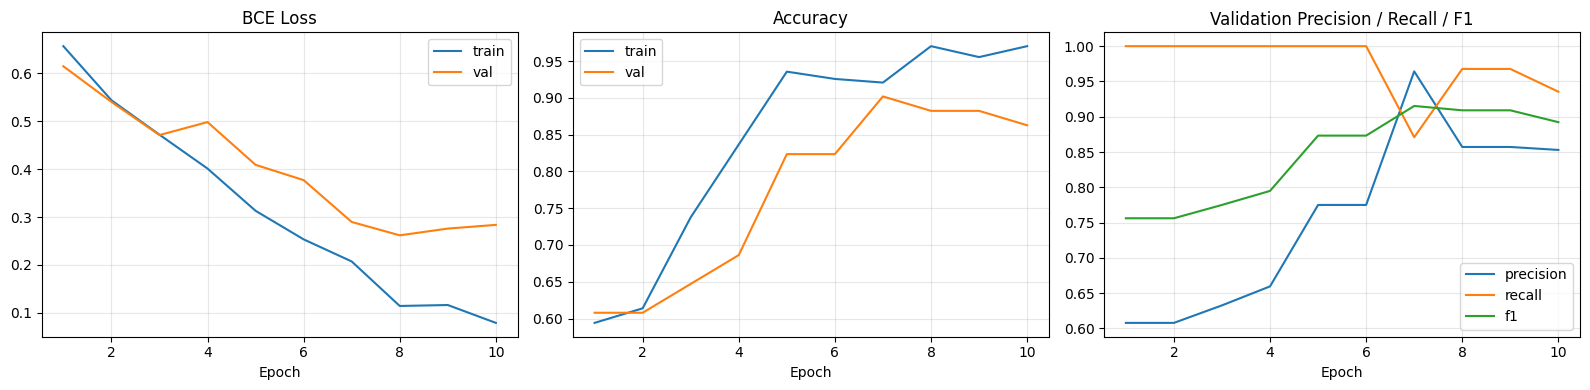

In [12]:
plot_history(history)

## 6. Try a single image

In [13]:
sample_dir = os.path.join(DATA_DIR, "yes")
sample_path = os.path.join(sample_dir, sorted(os.listdir(sample_dir))[0])
label, prob = predict_image(model, sample_path, cfg)
print(f"{os.path.basename(sample_path)}: {label} (tumor probability {prob:.3f})")

Y1.jpg: Tumor (tumor probability 0.988)


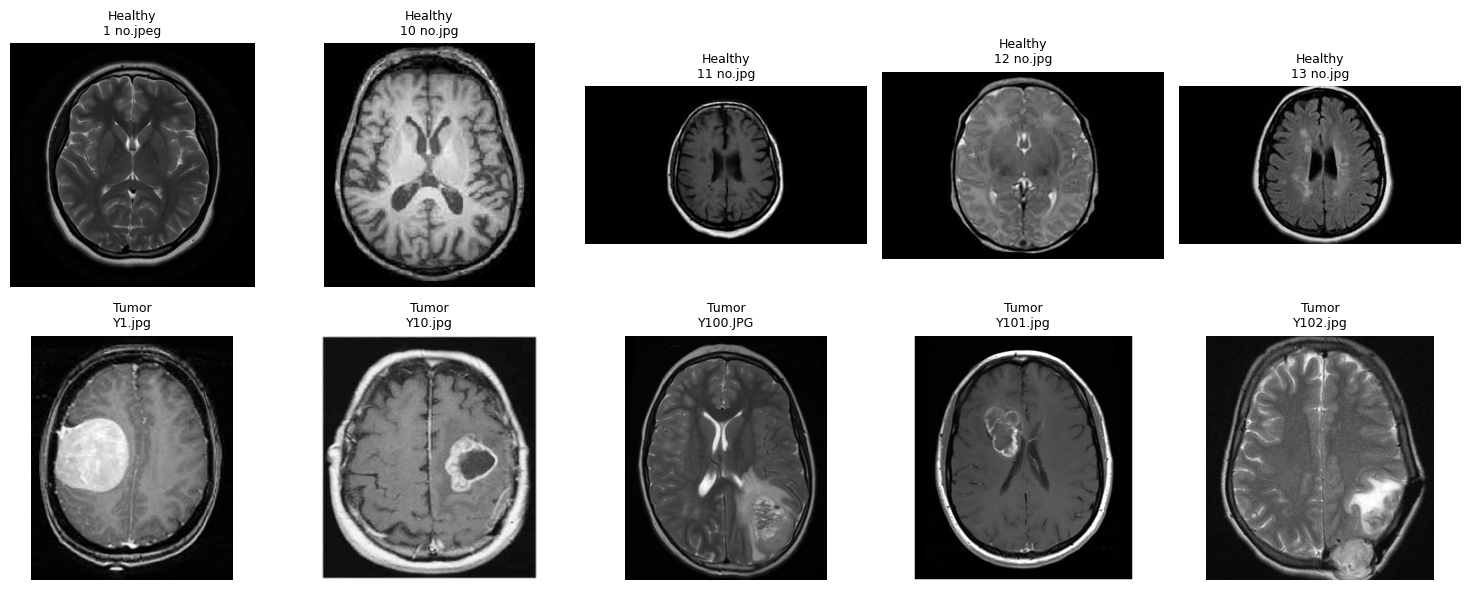

In [14]:
from PIL import Image
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for row, folder in enumerate(["no", "yes"]):
    names = sorted(os.listdir(os.path.join(DATA_DIR, folder)))[:5]
    for ax, n in zip(axes[row], names):
        ax.imshow(Image.open(os.path.join(DATA_DIR, folder, n)).convert("L"), cmap="gray")
        ax.set_title(f"{'Healthy' if folder == 'no' else 'Tumor'}\n{n}", fontsize=9)
        ax.axis("off")
plt.tight_layout()
plt.show()

In [15]:
from google.colab import files
uploaded = files.upload()   # opens a file picker
for name in uploaded:
    gray_path = "gray_" + name
    Image.open(name).convert("L").save(gray_path)   # remove the color tint
    label, prob = predict_image(model, gray_path, cfg)
    print(f"{name}: {label} (tumor probability {prob:.3f})")

Saving images.jpg to images.jpg
images.jpg: Tumor (tumor probability 0.824)
